In [272]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [273]:
# Read the csv file
df = pd.read_csv(r"C:\Users\vsh00\OneDrive - Rutgers University\python\AI-Project\IAL-Projects\Project 1\David\DataFiles\robot_data.csv")
# Trimmed dataframe that removes entries where the steps to completion were less than 15. 
df_trimmed = df[df['steps_till_completion']>5]

In [288]:
# Statistical values 
df.describe(), df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10932 entries, 0 to 10931
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   robotid                10932 non-null  int64  
 1   maze_size              10932 non-null  int64  
 2   fire_spread_variable   10932 non-null  float64
 3   steps_till_completion  10932 non-null  int64  
 4   successful             10932 non-null  bool   
dtypes: bool(1), float64(1), int64(3)
memory usage: 352.4 KB


(            robotid     maze_size  fire_spread_variable  steps_till_completion
 count  10932.000000  10932.000000          10932.000000           10932.000000
 mean       2.568240     79.965240              0.703366              45.919502
 std        1.178828      0.833104              0.162626              23.321170
 min        1.000000     60.000000              0.400000               0.000000
 25%        2.000000     80.000000              0.600000              28.000000
 50%        2.000000     80.000000              0.700000              43.000000
 75%        4.000000     80.000000              0.800000              61.000000
 max        4.000000     80.000000              1.000000             159.000000,
 None)

### Total Success Rates

In [275]:
# Sum up successful attempts by each robot
success_counts = df.groupby('robotid')['successful'].sum()
# Get total count of attempts by each robot
total_counts = df.groupby('robotid')['successful'].count()

# Get percentage of total successes
success_rate = success_counts/total_counts 
success_rate

robotid
1    0.610698
2    0.624569
3    0.632584
4    0.632229
Name: successful, dtype: float64

### Success Rates By Q Value (Fire_spread)


In [276]:
success_counts = df.groupby(['robotid', 'fire_spread_variable'])['successful'].sum()
total_counts = df.groupby(['robotid', 'fire_spread_variable'])['successful'].count()

success_rate_by_q = success_counts/total_counts 

success_rate_by_q = success_rate_by_q.reset_index().sort_values(['fire_spread_variable', 'robotid'])
success_rate_by_q


,robotid,fire_spread_variable,successful
0,1,0.4,0.781457
7,2,0.4,0.790000
14,3,0.4,0.770000
21,4,0.4,0.795000
1,1,0.5,0.680000
8,2,0.5,0.755000
15,3,0.5,0.742857
22,4,0.5,0.718690
2,1,0.6,0.628141
9,2,0.6,0.670000


In [277]:
# Group the robotid and fire_spread_variable by their successes
success_rate = df.groupby(['fire_spread_variable', 'robotid'])['successful'].mean().reset_index()

# Trimmed success rate
success_rate_trimmed = df_trimmed.groupby(['fire_spread_variable', 'robotid'])['successful'].mean().reset_index()


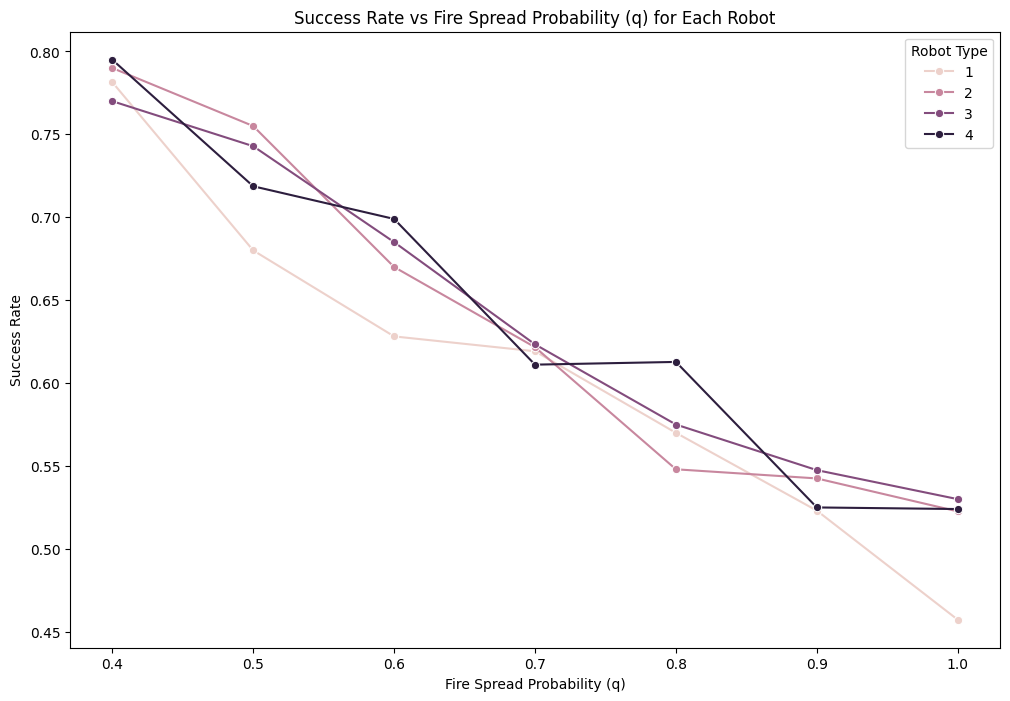

In [278]:

plt.figure(figsize=(12, 8))

# line plot for each robot type
sns.lineplot(data=success_rate, x='fire_spread_variable', y='successful', hue='robotid', marker='o')
plt.title('Success Rate vs Fire Spread Probability (q) for Each Robot')
plt.xlabel('Fire Spread Probability (q)')
plt.ylabel('Success Rate')
plt.legend(title='Robot Type')

plt.show()

### DataPoints that were successful

In [284]:
df_successful = df[df['successful']==True]



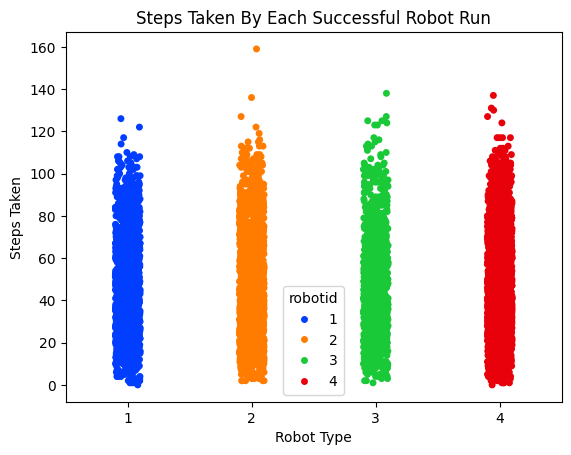

In [289]:
sns.stripplot(x='robotid', y = 'steps_till_completion', hue='robotid',data=df_successful, palette='bright')
plt.title('Steps Taken By Each Successful Robot Run')
plt.xlabel('Robot Type')
plt.ylabel('Steps Taken')
plt.show()


In [294]:
df_successful.info()

df_successful.groupby('robotid')['steps_till_completion'].mean()

<class 'pandas.core.frame.DataFrame'>
Index: 6832 entries, 0 to 10931
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   robotid                6832 non-null   int64  
 1   maze_size              6832 non-null   int64  
 2   fire_spread_variable   6832 non-null   float64
 3   steps_till_completion  6832 non-null   int64  
 4   successful             6832 non-null   bool   
dtypes: bool(1), float64(1), int64(3)
memory usage: 273.5 KB


robotid
1    47.885645
2    48.834254
3    48.219361
4    47.674512
Name: steps_till_completion, dtype: float64